# Studying Ground-State Energy Estimation Through Quantum Sampling
### Qiskit Fall Fest 2026 — Team Mensia
**Challenge:** Beginner Notebook — `01_sample_then_diagonalize.ipynb`

## Project summary
This notebook demonstrates the mechanics of sample-based quantum diagonalization (SQD) on a small transverse-field Ising chain. Qiskit constructs the Hamiltonian and generates computational-basis measurement samples from a quantum circuit. The observed bitstrings define a reduced subspace; NumPy then diagonalizes the Hamiltonian restricted to that subspace.

**Scope and limitation:** To keep this beginner demonstration controlled, the circuit is initialized with the exact ground-state vector calculated classically. Therefore, this is an educational demonstration of the sampling-and-subspace-diagonalization workflow, not a method for discovering an unknown ground state. It uses Qiskit's local `StatevectorSampler`, not quantum hardware, and makes no quantum-advantage claim.

## 1. Setup


In [1]:
%pip -q install "qiskit>=1.0" numpy pandas matplotlib
%pip install qiskit qiskit[visualization]
%pip install "numpy>=2.3.2" "qiskit==2.5.1" "matplotlib==3.11.1" "pylatexenc==2.10"


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorSampler

SEED = 20261021
N = 8
G = 0.4
SHOT_COUNTS = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
REPETITIONS = 30
rng = np.random.default_rng(SEED)

## 2. Build the transverse-field Ising Hamiltonian with Qiskit\nWe use open boundary conditions and  $$H \;=\; -\sum_{i} Z_i Z_{i+1} \;-\; g \sum_i X_i$$ The Hamiltonian is represented as a Qiskit `SparsePauliOp`. For this small system, we also convert it to a dense matrix to calculate an exact classical reference and reduced-subspace energies.

In [3]:
def build_hamiltonian(n, g):
    terms = [("ZZ", [i, i + 1], -1.0) for i in range(n - 1)]
    terms += [("X", [i], -g) for i in range(n)]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n).simplify()

H_op = build_hamiltonian(N, G)
H = np.asarray(H_op.to_matrix(), dtype=complex)
eigenvalues, eigenvectors = np.linalg.eigh(H)
E0 = float(eigenvalues[0].real)
ground_state = eigenvectors[:, 0]

print(f"Number of qubits: {N}")
print(f"Transverse field g: {G}")
print(f"Exact classical reference ground-state energy: {E0:.10f}")

Number of qubits: 8
Transverse field g: 0.4
Exact classical reference ground-state energy: -7.4055913441


## 3. Prepare and measure a circuit using Qiskit
The exact ground-state vector is used here only to create a controlled sampling distribution. The circuit is executed through Qiskit's local `StatevectorSampler`. A practical research workflow would prepare an approximate state with an ansatz and would not assume knowledge of the exact ground state.

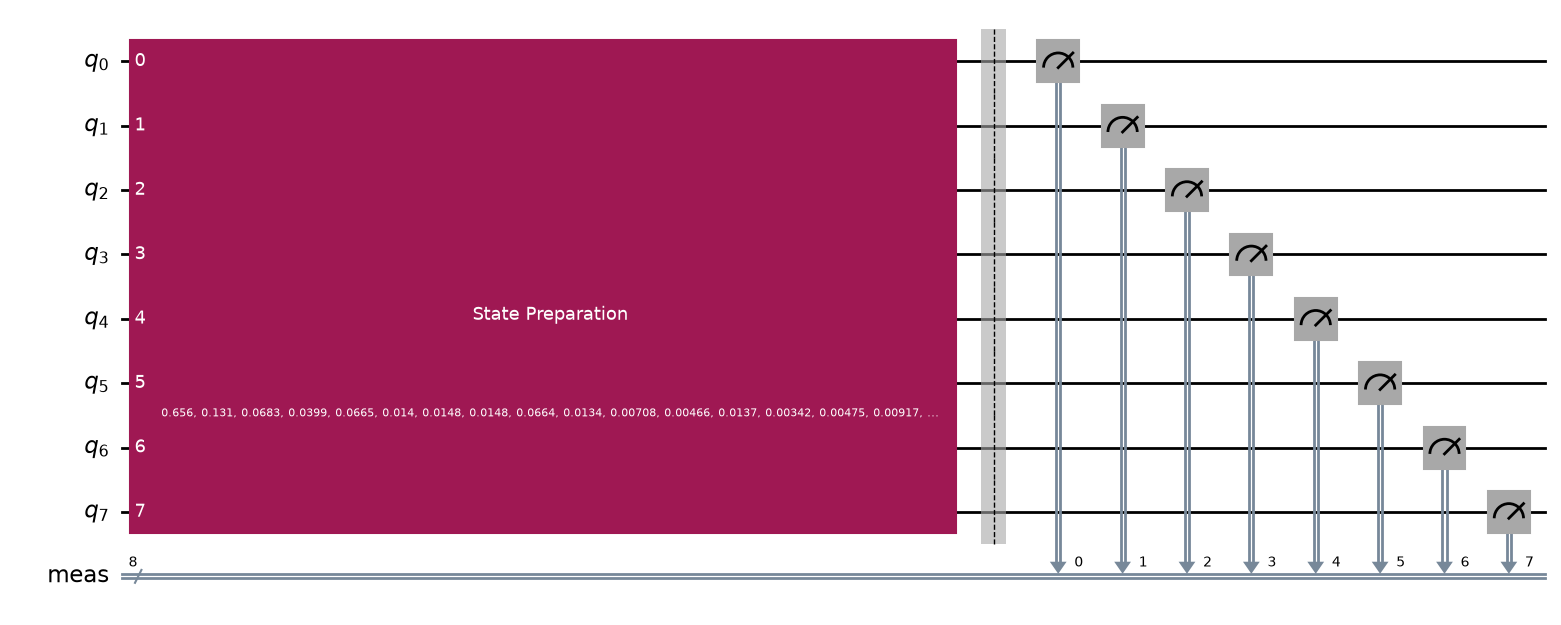

In [4]:
def make_sampling_circuit(statevector, n):
    qc = QuantumCircuit(n)
    qc.prepare_state(statevector, list(range(n)))
    qc.measure_all()
    return qc

sampling_circuit = make_sampling_circuit(ground_state, N)
sampling_circuit.draw("mpl")

In [5]:
sampler = StatevectorSampler(seed=SEED)

def sample_counts(shots):
    result = sampler.run([sampling_circuit], shots=int(shots)).result()[0]
    return result.data.meas.get_counts()

# Small test run to verify sampling works
example_counts = sample_counts(256)
print(example_counts)

{'00000000': 134, '11111111': 94, '10000000': 7, '11111110': 6, '01000000': 1, '10000010': 1, '00000101': 1, '00001000': 1, '11111011': 3, '01111111': 2, '11110111': 1, '00100000': 1, '00000011': 1, '00010100': 1, '00000001': 1, '11011111': 1}


## 4. Form the sampled subspace and diagonalize it
Each measured bitstring is interpreted as a computational-basis index. We retain the unique observed states and diagonalize the Hamiltonian matrix projected onto those states. We compare with a random subspace of the same dimension.

Because the subspace is a restriction of the full Hilbert space, its lowest eigenvalue should be greater than or equal to the exact full-space ground-state energy, up to numerical roundoff.

In [6]:
def bitstring_to_index(bitstring):
    return int(bitstring.replace(" ", ""), 2)

def reduced_ground_energy(states):
    states = np.array(sorted(set(int(s) for s in states)), dtype=int)
    H_sub = H[np.ix_(states, states)]
    return float(np.linalg.eigvalsh(H_sub)[0].real)

def one_trial(shots, trial_rng):
    counts = sample_counts(shots)
    sampled_states = np.array(sorted(bitstring_to_index(s) for s in counts.keys()), dtype=int)
    k = len(sampled_states)
    random_states = trial_rng.choice(2**N, size=k, replace=False)
    sampled_energy = reduced_ground_energy(sampled_states)
    random_energy = reduced_ground_energy(random_states)
    return {
        "shots": int(shots),
        "unique_sampled_states": int(k),
        "sampled_energy": sampled_energy,
        "random_energy": random_energy,
        "sampled_abs_error": abs(sampled_energy - E0),
        "random_abs_error": abs(random_energy - E0),
    }

## 5. Experiment: effect of the number of samples
For each shot count, repeat the experiment. The plotted values are averages across repetitions; error bars show one standard deviation. Finite-sample results can fluctuate and are not guaranteed to improve monotonically.

In [7]:
records = []
for shots in SHOT_COUNTS:
    for rep in range(REPETITIONS):
        row = one_trial(shots, rng)
        row["repetition"] = rep + 1
        records.append(row)

results = pd.DataFrame(records)
summary = (
    results.groupby("shots")
    .agg(
        mean_sampled_energy=("sampled_energy", "mean"),
        sd_sampled_energy=("sampled_energy", "std"),
        mean_random_energy=("random_energy", "mean"),
        sd_random_energy=("random_energy", "std"),
        mean_unique_states=("unique_sampled_states", "mean"),
        mean_sampled_abs_error=("sampled_abs_error", "mean"),
        mean_random_abs_error=("random_abs_error", "mean"),
    )
    .reset_index()
)
summary

,shots,mean_sampled_energy,sd_sampled_energy,mean_random_energy,sd_random_energy,mean_unique_states,mean_sampled_abs_error,mean_random_abs_error
0,16,-7.000000,0.0,-2.213333,1.999954,2.0,0.405591,5.192258
1,32,-7.077033,0.0,-2.630555,1.595880,4.0,0.328558,4.775037
2,64,-7.152313,0.0,-3.632943,0.948297,9.0,0.253278,3.772649
3,128,-7.219976,0.0,-4.362250,1.497117,11.0,0.185616,3.043342
4,256,-7.258384,0.0,-4.497980,1.368431,16.0,0.147208,2.907612
5,512,-7.356189,0.0,-4.897585,1.220788,25.0,0.049403,2.508006
6,1024,-7.372454,0.0,-5.322903,1.045117,31.0,0.033137,2.082688
7,2048,-7.384186,0.0,-5.727132,1.106286,42.0,0.021406,1.678460
8,4096,-7.386607,0.0,-5.957571,0.937889,50.0,0.018985,1.448021


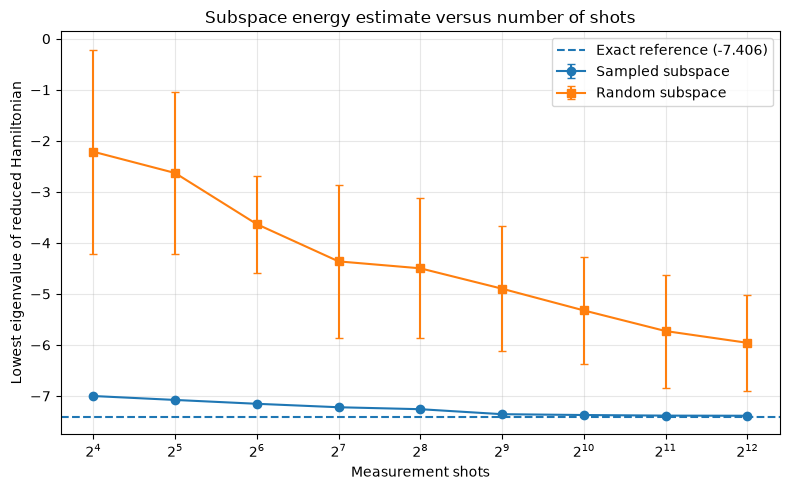

In [8]:
plt.figure(figsize=(8, 5))
plt.errorbar(summary["shots"], summary["mean_sampled_energy"], yerr=summary["sd_sampled_energy"], marker="o", capsize=3, label="Sampled subspace")
plt.errorbar(summary["shots"], summary["mean_random_energy"], yerr=summary["sd_random_energy"], marker="s", capsize=3, label="Random subspace")
plt.axhline(E0, linestyle="--", label=f"Exact reference ({E0:.3f})")
plt.xscale("log", base=2)
plt.xlabel("Measurement shots")
plt.ylabel("Lowest eigenvalue of reduced Hamiltonian")
plt.title("Subspace energy estimate versus number of shots")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

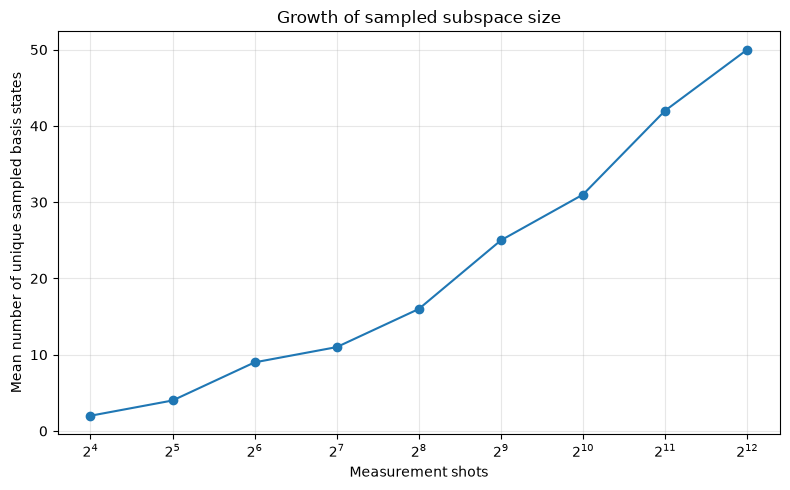

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(summary["shots"], summary["mean_unique_states"], marker="o")
plt.xscale("log", base=2)
plt.xlabel("Measurement shots")
plt.ylabel("Mean number of unique sampled basis states")
plt.title("Growth of sampled subspace size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Export results
The CSV files are generated when the notebook is run.

In [11]:
results.to_csv("team_mensia_sqd_trial_results.csv", index=False)
summary.to_csv("team_mensia_sqd_summary.csv", index=False)
print("Saved trial-level and summary CSV files.")

Saved trial-level and summary CSV files.


## 7. Interpretation and limitations
- Qiskit is used to encode the Hamiltonian as a `SparsePauliOp`, construct the circuit, and generate measurement samples with `StatevectorSampler`.
- NumPy performs exact diagonalization for the reference and classical diagonalization of the reduced matrices.
- More shots can reveal more of the measurement distribution and enlarge the sampled subspace, but the energy estimate need not improve monotonically for every finite run.
- A random subspace is a simple baseline, not a comprehensive benchmark against other algorithms.
- The exact ground-state initialization makes the experiment circular as a ground-state-discovery algorithm. It isolates the sampling and subspace construction stages for learning purposes.
- This is a local statevector simulation, not a hardware experiment. No quantum speedup or quantum advantage is claimed.

## 8. AI assistance disclosure
AI tools assisted with drafting, code organization, and explanatory text.

In [12]:
print(summary[[
    "shots",
    "mean_sampled_energy",
    "mean_random_energy"
]])

   shots  mean_sampled_energy  mean_random_energy
0     16            -7.000000           -2.213333
1     32            -7.077033           -2.630555
2     64            -7.152313           -3.632943
3    128            -7.219976           -4.362250
4    256            -7.258384           -4.497980
5    512            -7.356189           -4.897585
6   1024            -7.372454           -5.322903
7   2048            -7.384186           -5.727132
8   4096            -7.386607           -5.957571


In [13]:
unique_state_results = []

for shots in [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]:
    counts = sample_counts(shots)

    unique_states = {
        int(bitstring.replace(" ", ""), 2)
        for bitstring in counts.keys()
    }

    unique_state_results.append({
        "shots": shots,
        "unique_sampled_states": len(unique_states)
    })

unique_df = pd.DataFrame(unique_state_results)
print(unique_df.to_string(index=False))

 shots  unique_sampled_states
    16                      2
    32                      4
    64                      9
   128                     11
   256                     16
   512                     25
  1024                     31
  2048                     42
  4096                     50
